In [33]:
"""Complete B-MPC reproduction: planning, closed-loop control, and repeated trials.
Run top to bottom. Dependencies: numpy, pandas, matplotlib, torch.
The default entry is an explicitly shortened demo; Settings retains T=300.
"""
from dataclasses import dataclass, asdict, replace
from pathlib import Path
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

torch.set_num_threads(1)  # Tiny matrices: avoid excessive CPU threading overhead.


@dataclass(frozen=True)
class Settings:
    system: str = "double_integrator"
    n: int = 6
    p: int = 3
    m: int = 3
    T: int = 300
    H: int = 15
    trials: int = 10
    horizons: tuple = (5, 10, 15, 20, 25, 30)
    rho: float = 0.95
    h: float = 0.3
    c0: float = 0.01
    c1: float = 3.0
    r_scale: float = 1.0
    sigma_w: float = 0.1
    sigma_z: float = 1.0
    lbfgs_lr: float = 0.8
    lbfgs_outer_steps: int = 20
    restarts: int = 1
    lbfgs_history_size: int = 100
    lbfgs_line_search_fn: object = "strong_wolfe"  # Numerical choice, not specified by paper.
    lbfgs_tolerance_grad: float = 1e-7
    lbfgs_tolerance_change: float = 1e-9
    lbfgs_max_iter: int = 20  # PER optimizer.step(); previously 1000.
    system_seed: int = 20261007
    noise_seed: int = 12345
    optimizer_seed: int = 54321


def make_settings(system="double_integrator"):
    if system == "double_integrator":
        return Settings()
    if system == "random":
        return Settings(system=system, H=10, sigma_z=0.1)
    raise ValueError("system must be 'double_integrator' or 'random'")


def build_system(cfg):
    n, p, m = cfg.n, cfg.p, cfg.m
    if cfg.system == "double_integrator":
        if (n, p, m) != (6, 3, 3):
            raise ValueError("double_integrator requires (n,p,m) = (6,3,3)")
        A = np.kron(np.eye(3), [[cfg.rho, cfg.h], [0., cfg.rho]])
        B, C0, Ck = np.zeros((n, p)), np.zeros((m, n)), np.zeros((p, m, n))
        for k in range(p):
            B[2*k+1, k], C0[k, 2*k], Ck[k, k, 2*k] = cfg.h, cfg.c0, cfg.c1
    elif cfg.system == "random":
        rng = np.random.default_rng(cfg.system_seed)
        A = rng.normal(size=(n, n))
        A *= cfg.rho / np.max(np.abs(np.linalg.eigvals(A)))
        B = rng.normal(size=(n, p)) / np.sqrt(n)
        C0 = cfg.c0 * rng.normal(size=(m, n)) / np.sqrt(m)
        Ck = rng.normal(size=(p, m, n)) / np.sqrt(m)
    else:
        raise ValueError("Unknown system")
    return dict(A=A, B=B, C0=C0, Ck=Ck, Q=np.eye(n), QT=np.eye(n),
                R=cfg.r_scale*np.eye(p), W=cfg.sigma_w**2*np.eye(n),
                V=cfg.sigma_z**2*np.eye(m), mu0=np.zeros(n), P0=np.eye(n))


def observation_matrix(s, u):
    return s["C0"] + np.einsum("k,kij->ij", u, s["Ck"])


def make_trial(cfg, trial_id, system=None):
    s = build_system(cfg) if system is None else system
    rng = np.random.default_rng(np.random.SeedSequence([cfg.noise_seed, trial_id]))
    return dict(x0=rng.multivariate_normal(s["mu0"], s["P0"]),
                w=rng.multivariate_normal(np.zeros(cfg.n), s["W"], cfg.T),
                z=rng.multivariate_normal(np.zeros(cfg.m), s["V"], cfg.T))


def initial_controls(cfg, trial_id, t, restart=0):
    seed = [cfg.optimizer_seed, trial_id, t, cfg.H] + ([restart] if restart else [])
    rng = np.random.default_rng(np.random.SeedSequence(seed))
    return rng.normal(size=(cfg.H, cfg.p)) / np.sqrt(cfg.H)


def tensor(x):
    return torch.as_tensor(x, dtype=torch.float64, device="cpu").detach().clone()


def to_torch(system):
    return {k: tensor(v) for k, v in system.items()}




In [34]:
def belief_rollout(U, mu, P, s):
    """Deterministic planning surrogate: future innovations are set to zero."""
    A, B, Q, QT, R = (s[k] for k in ("A", "B", "Q", "QT", "R"))
    I = torch.eye(A.shape[0], dtype=U.dtype, device=U.device)
    mean_cost, cov_cost, input_cost = (U.new_zeros(()) for _ in range(3))
    means, covs = [mu], [P]
    for u in U:
        mean_cost = mean_cost + mu @ Q @ mu
        cov_cost = cov_cost + torch.trace(Q @ P)
        input_cost = input_cost + u @ R @ u
        C = s["C0"] + torch.einsum("k,kij->ij", u, s["Ck"])
        K = torch.linalg.solve(C @ P @ C.T + s["V"], C @ P).T
        D = I - K @ C
        P = A @ (D @ P @ D.T + K @ s["V"] @ K.T) @ A.T + s["W"]
        P = (P + P.T) / 2
        mu = A @ mu + B @ u
        means.append(mu)
        covs.append(P)
    parts = torch.stack([mean_cost + mu @ QT @ mu,
                         cov_cost + torch.trace(QT @ P), input_cost])
    return parts.sum(), torch.stack(means), torch.stack(covs), parts


def sep_gains(s, H):
    """Exact Riccati solution of the H-step deterministic LQ problem: u=L@mu."""
    A, B, Q, R, S = [np.asarray(s[k]) for k in ("A", "B", "Q", "R", "QT")]
    gains = []
    for _ in range(H):
        L = -np.linalg.solve(R + B.T @ S @ B, B.T @ S @ A)
        S = Q + A.T @ S @ (A + B @ L)
        S = (S + S.T) / 2
        gains.append(L)
    return np.array(gains[::-1])


def sep_mpc_sequence(mu, s, H):
    x, U = tensor(mu).numpy(), []
    A, B = np.asarray(s["A"]), np.asarray(s["B"])
    for L in sep_gains(s, H):
        u = L @ x
        U.append(u)
        x = A @ x + B @ u
    return tensor(np.array(U))


def update_belief(mu, P, u, y, s):
    """Condition on y_t, then predict x_{t+1}; stable Joseph covariance form."""
    A, B, W, V = (s[k] for k in ("A", "B", "W", "V"))
    C = observation_matrix(s, u)
    K = np.linalg.solve(C @ P @ C.T + V, C @ P).T
    posterior_mu = mu + K @ (y - C @ mu)
    D = np.eye(len(mu)) - K @ C
    P = A @ (D @ P @ D.T + K @ V @ K.T) @ A.T + W
    return A @ posterior_mu + B @ u, (P + P.T) / 2




In [35]:
def solve_bmpc(cfg, system, mu=None, P=None, trial_id=0, t=0, U_init=None, details=True):
    if min(cfg.H, cfg.restarts, cfg.lbfgs_outer_steps, cfg.lbfgs_max_iter) < 1:
        raise ValueError("H, restarts and optimizer iteration limits must be positive")
    s = to_torch(system)
    mu, P = tensor(system["mu0"] if mu is None else mu), tensor(system["P0"] if P is None else P)
    options = dict(lr=cfg.lbfgs_lr, max_iter=cfg.lbfgs_max_iter,
                   history_size=cfg.lbfgs_history_size, line_search_fn=cfg.lbfgs_line_search_fn,
                   tolerance_grad=cfg.lbfgs_tolerance_grad, tolerance_change=cfg.lbfgs_tolerance_change)
    history, starts, closure_calls = [], [], 0
    best_loss, best_U, best_index = float("inf"), None, None
    start = time.perf_counter()
    for restart in range(cfg.restarts):
        init = U_init if restart == 0 and U_init is not None else initial_controls(cfg, trial_id, t, restart)
        U = tensor(init).requires_grad_(True)
        if tuple(U.shape) != (cfg.H, cfg.p):
            raise ValueError(f"Expected U_init.shape={(cfg.H, cfg.p)}, got {tuple(U.shape)}")
        starts.append(U.detach().clone())
        optimizer = torch.optim.LBFGS([U], **options)

        def closure():
            nonlocal closure_calls
            optimizer.zero_grad(set_to_none=True)
            loss = belief_rollout(U, mu, P, s)[0]
            if not torch.isfinite(loss):
                raise FloatingPointError(f"Non-finite planning loss at t={t}, restart={restart}")
            loss.backward()
            closure_calls += 1
            return loss

        def record(outer):
            nonlocal best_loss, best_U, best_index
            loss, _, _, parts = belief_rollout(U, mu, P, s)
            grad, = torch.autograd.grad(loss, U)
            if not (torch.isfinite(loss) and torch.isfinite(grad).all()):
                raise FloatingPointError(f"Non-finite objective/gradient at t={t}")
            row = dict(restart=restart, outer_step=outer, objective=float(loss.detach()),
                       gradient_inf=float(grad.abs().max()), closure_evaluations=closure_calls,
                       internal_iterations=int(optimizer.state.get(U, {}).get("n_iter", 0)),
                       mean_cost=float(parts[0].detach()), covariance_cost=float(parts[1].detach()),
                       input_cost=float(parts[2].detach()), elapsed_seconds=time.perf_counter()-start)
            history.append(row)
            if row["objective"] < best_loss:
                best_loss, best_U, best_index = row["objective"], U.detach().clone(), len(history)-1
            return row

        row = record(0)
        for outer in range(1, cfg.lbfgs_outer_steps + 1):
            if row["gradient_inf"] <= cfg.lbfgs_tolerance_grad:
                break
            before = U.detach().clone()
            optimizer.step(closure)
            row = record(outer)
            if float((U.detach()-before).abs().max()) <= cfg.lbfgs_tolerance_change:
                break  # Stagnation is NOT evidence that the gradient tolerance was met.

    hist = pd.DataFrame(history)
    hist["selected"] = hist.index == best_index
    selected = history[best_index]
    init = starts[selected["restart"]]
    diagnostics = dict(trial_id=trial_id, t=t, H=cfg.H, options=options,
                       selected_restart=selected["restart"], selected_outer=selected["outer_step"],
                       initial_objective=float(hist[hist.restart == selected["restart"]].iloc[0].objective),
                       final_objective=best_loss, gradient_inf=selected["gradient_inf"],
                       gradient_tolerance_met=selected["gradient_inf"] <= cfg.lbfgs_tolerance_grad,
                       closure_evaluations=closure_calls, elapsed_seconds=time.perf_counter()-start,
                       internal_iterations=int(hist.groupby("restart").internal_iterations.last().sum()),
                       first_action=best_U[0].tolist(), torch_version=torch.__version__,
                       note="Best recorded iterate; deterministic surrogate; no global-optimum guarantee.")
    result = dict(U=best_U.numpy().copy(), u0=best_U[0].numpy().copy(), history=hist,
                  diagnostics=diagnostics, config=asdict(cfg))
    if details:
        candidates = {"Zero": torch.zeros_like(best_U), "Sep-MPC": sep_mpc_sequence(mu, s, cfg.H),
                      "Random init": init, "B-MPC": best_U}
        trajectories, rows = {}, []
        with torch.no_grad():
            for name, controls in candidates.items():
                loss, means, covs, parts = belief_rollout(controls, mu, P, s)
                trajectories[name] = dict(U=controls.numpy().copy(), mean=means.numpy(), covariance=covs.numpy())
                rows.append(dict(candidate=name, objective=float(loss), mean_cost=float(parts[0]),
                                 covariance_cost=float(parts[1]), input_cost=float(parts[2])))
        cov = trajectories["B-MPC"]["covariance"]
        diagnostics.update(min_predicted_covariance_eigenvalue=float(np.linalg.eigvalsh(cov).min()),
                           max_covariance_asymmetry=float(np.abs(cov-cov.transpose(0, 2, 1)).max()))
        result.update(trajectories=trajectories, comparison=pd.DataFrame(rows).set_index("candidate"))
    return result




In [36]:
def run_closed_loop(cfg, system=None, trial_id=0, progress_every=25):
    if cfg.T < 1:
        raise ValueError("T must be positive")
    s = build_system(cfg) if system is None else system
    trial = make_trial(cfg, trial_id, s)
    A, B, Q, R, QT = (s[k] for k in ("A", "B", "Q", "R", "QT"))
    LT, LH = sep_gains(s, cfg.T), sep_gains(s, cfg.H)
    trajectories, rows, summaries, histories, solver_rows = {}, [], [], [], []
    for name in ("Zero", "Sep", "Sep-MPC", "B-MPC"):
        x, mu, P = trial["x0"].copy(), s["mu0"].copy(), s["P0"].copy()
        X, M, Ps, U, Y, costs = [x], [mu], [P], [], [], []
        cumulative = 0.
        start = time.perf_counter()
        for t in range(cfg.T):
            if name == "B-MPC":
                r = solve_bmpc(cfg, s, mu, P, trial_id, t, details=False)
                u = r["u0"]
                histories.append(r["history"].assign(t=t, trial_id=trial_id))
                solver_rows.append({k: r["diagnostics"][k] for k in
                                    ("t", "initial_objective", "final_objective", "gradient_inf",
                                     "gradient_tolerance_met", "closure_evaluations", "elapsed_seconds")})
            else:
                u = np.zeros(cfg.p) if name == "Zero" else (LT[t] if name == "Sep" else LH[0]) @ mu
            y = observation_matrix(s, u) @ x + trial["z"][t]
            cost = float(x @ Q @ x + u @ R @ u)
            mu, P = update_belief(mu, P, u, y, s)
            x = A @ x + B @ u + trial["w"][t]
            cumulative += cost
            rows.append(dict(method=name, t=t, cost=cost, cumulative=cumulative,
                             u_norm=np.linalg.norm(u), x_next_norm=np.linalg.norm(x),
                             mu_next_norm=np.linalg.norm(mu), trace_P_next=np.trace(P),
                             error_next_norm=np.linalg.norm(x-mu)))
            X.append(x); M.append(mu); Ps.append(P)
            U.append(u); Y.append(y); costs.append(cost)
            if name == "B-MPC" and progress_every and (t == 0 or (t+1) % progress_every == 0 or t+1 == cfg.T):
                print(f"B-MPC trial={trial_id}, H={cfg.H}: {t+1}/{cfg.T}, {time.perf_counter()-start:.1f}s", flush=True)
        X, U = np.array(X), np.array(U)
        terminal = float(x @ QT @ x)
        trajectories[name] = dict(x=X, mu=np.array(M), P=np.array(Ps), u=U,
                                  y=np.array(Y), cost=np.r_[costs, terminal])
        summaries.append(dict(method=name, state_cost=np.einsum("ti,ij,tj->", X[:-1], Q, X[:-1]),
                              input_cost=np.einsum("ti,ij,tj->", U, R, U), terminal_cost=terminal,
                              total_cost=cumulative+terminal, elapsed_seconds=time.perf_counter()-start))
    return dict(trajectories=trajectories, updates=pd.DataFrame(rows),
                comparison=pd.DataFrame(summaries).set_index("method"),
                history=pd.concat(histories, ignore_index=True), solver=pd.DataFrame(solver_rows),
                config=asdict(cfg), trial_id=trial_id)




In [37]:
def save_result(result, output_dir):
    out = Path(output_dir)
    out.mkdir(parents=True, exist_ok=True)
    for key in ("comparison", "updates", "history", "solver"):
        if key in result:
            result[key].to_csv(out / f"{key}.csv", index=key == "comparison")
    arrays = {f"{name.replace(' ', '_').replace('-', '_')}_{k}": v
              for name, a in result["trajectories"].items() for k, v in a.items()}
    np.savez_compressed(out / "trajectories.npz", **arrays)
    with (out / "settings.json").open("w") as f:
        json.dump(dict(config=result["config"], trial_id=result.get("trial_id"),
                       diagnostics=result.get("diagnostics", {})), f, indent=2)
    return out


def report_and_plot(result, output_dir="bmpc_results/planning"):
    h, d, tr = result["history"], result["diagnostics"], result["trajectories"]
    print("PLANNING: all candidates evaluated on the SAME deterministic surrogate.")
    print(result["comparison"].round(5).to_string())
    print("\nEvery recorded optimizer round (selected=True is the returned iterate):")
    print(h[["restart", "outer_step", "objective", "gradient_inf", "closure_evaluations", "selected"]].to_string(index=False))
    print(f"\nFirst action: {result['u0']}; gradient tolerance met: {d['gradient_tolerance_met']}")
    print(f"Min covariance eigenvalue: {d['min_predicted_covariance_eigenvalue']:.3e}; "
          f"closures: {d['closure_evaluations']}; elapsed: {d['elapsed_seconds']:.2f}s")
    print("\nPredicted actions (execute ONLY row 0):")
    print(pd.DataFrame(result["U"], columns=[f"u{k+1}" for k in range(result["U"].shape[1])]).round(5).to_string())
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
    for restart, a in h.groupby("restart"):
        axes[0, 0].plot(a.outer_step, a.objective, ".-", label=f"restart {restart}")
        axes[0, 1].semilogy(a.outer_step, np.maximum(a.gradient_inf, 1e-16), ".-")
    axes[0, 0].set(title="Surrogate objective", xlabel="Optimizer outer call")
    axes[0, 0].legend()
    axes[0, 1].axhline(d["options"]["tolerance_grad"], color="gray", ls="--")
    axes[0, 1].set(title="Gradient infinity norm", xlabel="Optimizer outer call")
    for k in range(result["U"].shape[1]):
        axes[0, 2].plot(result["U"][:, k], ".-", label=f"u{k+1}")
    axes[0, 2].set(title="Selected planned actions", xlabel="Prediction step j")
    axes[0, 2].legend()
    for name, a in tr.items():
        axes[1, 0].plot(np.trace(a["covariance"], axis1=1, axis2=2), label=name)
        axes[1, 1].plot(np.linalg.norm(a["mean"], axis=1), label=name)
    axes[1, 0].set(title="Predicted trace(P)", xlabel="Prediction step j")
    axes[1, 1].set(title="Predicted mean norm", xlabel="Prediction step j")
    axes[1, 0].legend(); axes[1, 1].legend()
    result["comparison"][["mean_cost", "covariance_cost", "input_cost"]].plot.bar(stacked=True, ax=axes[1, 2], rot=15)
    axes[1, 2].set(title="Surrogate cost decomposition", xlabel="")
    for ax in axes.flat:
        ax.grid(alpha=.2)
    fig.suptitle("One planning solve — predictions, not a closed-loop experiment")
    fig.savefig(save_result(result, output_dir) / "planning.png", dpi=160)
    plt.show()
    return fig


def report_closed_loop(result, output_dir="bmpc_results/closed_loop", print_steps=True):
    tr, table = result["trajectories"], result["comparison"]
    print("CLOSED LOOP: realized costs, including the terminal state cost (one trial).")
    print(table.round(5).to_string())
    if print_steps:
        print("\nEach row: action/cost at t; updated state and belief at t+1.\n"
              "The cumulative column excludes the terminal cost; total_cost above includes it.")
        print(result["updates"].sort_values(["t", "method"]).round(4).to_string(index=False))
        print("\nEach B-MPC planning solve; these objectives are NOT realized costs:")
        print(result["solver"].to_string(index=False))
    print(f"\nSelected gradients meeting tolerance: {int(result['solver'].gradient_tolerance_met.sum())}/{len(result['solver'])}")
    print("Full beliefs/actions and all recorded optimizer rounds are saved, including unconverged runs.")
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
    styles = {"Zero": ("gray", ":"), "Sep": ("#2878B5", "--"),
              "Sep-MPC": ("#E68613", "-."), "B-MPC": ("#299D60", "-")}
    titles = ["Actual state norm", "Estimation error norm", "Prior uncertainty: trace(P)",
              "Executed control norm", "Cumulative realized cost (terminal at T)"]
    for name, a in tr.items():
        values = [np.linalg.norm(a["x"], axis=1), np.linalg.norm(a["x"]-a["mu"], axis=1),
                  np.trace(a["P"], axis1=1, axis2=2), np.linalg.norm(a["u"], axis=1), np.cumsum(a["cost"])]
        for ax, v, title in zip(axes.flat, values, titles):
            ax.plot(v, color=styles[name][0], ls=styles[name][1], label=name)
            ax.set(title=title, xlabel="Time t")
            ax.grid(alpha=.2)
            ax.legend(fontsize=8)
    table[["state_cost", "input_cost", "terminal_cost"]].plot.bar(stacked=True, ax=axes[1, 2], rot=15)
    axes[1, 2].set(title="Realized cost decomposition", xlabel="", ylabel="Cost")
    fig.suptitle("Independent closed-loop controllers — shared initial state and noise")
    fig.savefig(save_result(result, output_dir) / "closed_loop.png", dpi=160)
    plt.show()
    return fig


def run_planning_experiment(cfg, system=None, mu=None, P=None, trial_id=0, t=0,
                            output_dir="bmpc_results/planning", U_init=None):
    system = build_system(cfg) if system is None else system
    result = solve_bmpc(cfg, system, mu, P, trial_id, t, U_init)
    report_and_plot(result, output_dir)
    return result




In [38]:
def run_sweep(cfg, output_dir="bmpc_results/sweep", horizons=None):
    """Same system and paired x0/w/z across methods AND horizons; independent trials."""
    out = Path(output_dir)
    out.mkdir(parents=True, exist_ok=True)
    system, tables = build_system(cfg), []
    horizons = cfg.horizons if horizons is None else tuple(horizons)
    if cfg.trials < 1 or not horizons:
        raise ValueError("Need at least one trial and one horizon")
    for H in horizons:
        for trial_id in range(cfg.trials):
            print(f"\nH={H}, trial={trial_id+1}/{cfg.trials}", flush=True)
            r = run_closed_loop(replace(cfg, H=H), system, trial_id)
            save_result(r, out / f"H{H}_trial{trial_id}")
            tables.append(r["comparison"].reset_index().assign(H=H, trial_id=trial_id))
    raw = pd.concat(tables, ignore_index=True)
    summary = raw.groupby(["H", "method"])["total_cost"].agg(["mean", "std", "count"])
    summary["se"] = summary["std"] / np.sqrt(summary["count"])
    paired = raw.pivot(index=["H", "trial_id"], columns="method", values="total_cost")
    diff = (paired["B-MPC"] - paired["Sep-MPC"]).groupby(level="H").agg(["mean", "std", "count"])
    diff["se"] = diff["std"] / np.sqrt(diff["count"])
    raw.to_csv(out / "all_costs.csv", index=False)
    summary.to_csv(out / "summary.csv")
    diff.to_csv(out / "paired_bmpc_minus_sep_mpc.csv")
    print("\nMean realized cost and standard error across trials:", summary, sep="\n")
    print("\nPaired B-MPC minus Sep-MPC cost (negative favors B-MPC):", diff, sep="\n")
    fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
    for name in ("Zero", "Sep", "Sep-MPC", "B-MPC"):
        a = summary.xs(name, level="method")
        if cfg.trials > 1:
            ax.errorbar(a.index, a["mean"], yerr=a["se"], marker="o", capsize=3, label=name)
        else:
            ax.plot(a.index, a["mean"], "o-", label=name)
    ax.set(xlabel="Planning horizon H", ylabel="Realized total cost",
           title="Mean +/- one standard error" if cfg.trials > 1 else "One trial: no error bars")
    ax.legend(); ax.grid(alpha=.2)
    fig.savefig(out / "horizons.png", dpi=160)
    plt.show()
    return dict(raw=raw, summary=summary, paired_difference=diff)




In [39]:
cfg = make_settings("double_integrator")
#demo_cfg = replace(cfg, T=40, lbfgs_outer_steps=10, lbfgs_max_iter=50)
demo_cfg = cfg
system = build_system(demo_cfg)
print("实际运行参数：", asdict(demo_cfg))


实际运行参数： {'system': 'double_integrator', 'n': 6, 'p': 3, 'm': 3, 'T': 300, 'H': 15, 'trials': 10, 'horizons': (5, 10, 15, 20, 25, 30), 'rho': 0.95, 'h': 0.3, 'c0': 0.01, 'c1': 3.0, 'r_scale': 1.0, 'sigma_w': 0.1, 'sigma_z': 1.0, 'lbfgs_lr': 0.8, 'lbfgs_outer_steps': 20, 'restarts': 1, 'lbfgs_history_size': 100, 'lbfgs_line_search_fn': 'strong_wolfe', 'lbfgs_tolerance_grad': 1e-07, 'lbfgs_tolerance_change': 1e-09, 'lbfgs_max_iter': 20, 'system_seed': 20261007, 'noise_seed': 12345, 'optimizer_seed': 54321}


PLANNING: all candidates evaluated on the SAME deterministic surrogate.
             objective  mean_cost  covariance_cost  input_cost
candidate                                                     
Zero         177.93671    0.00000        177.93671     0.00000
Sep-MPC      177.93671    0.00000        177.93671     0.00000
Random init   53.65523    4.79540         45.43422     3.42561
B-MPC         37.12174    0.48919         27.63025     9.00230

Every recorded optimizer round (selected=True is the returned iterate):
 restart  outer_step  objective  gradient_inf  closure_evaluations  selected
       0           0  53.655230      7.316770                    0     False
       0           1  37.230974      0.064318                   21     False
       0           2  37.137375      0.024067                   42     False
       0           3  37.121743      0.000128                   63     False
       0           4  37.121743      0.000014                   69      True
       0       

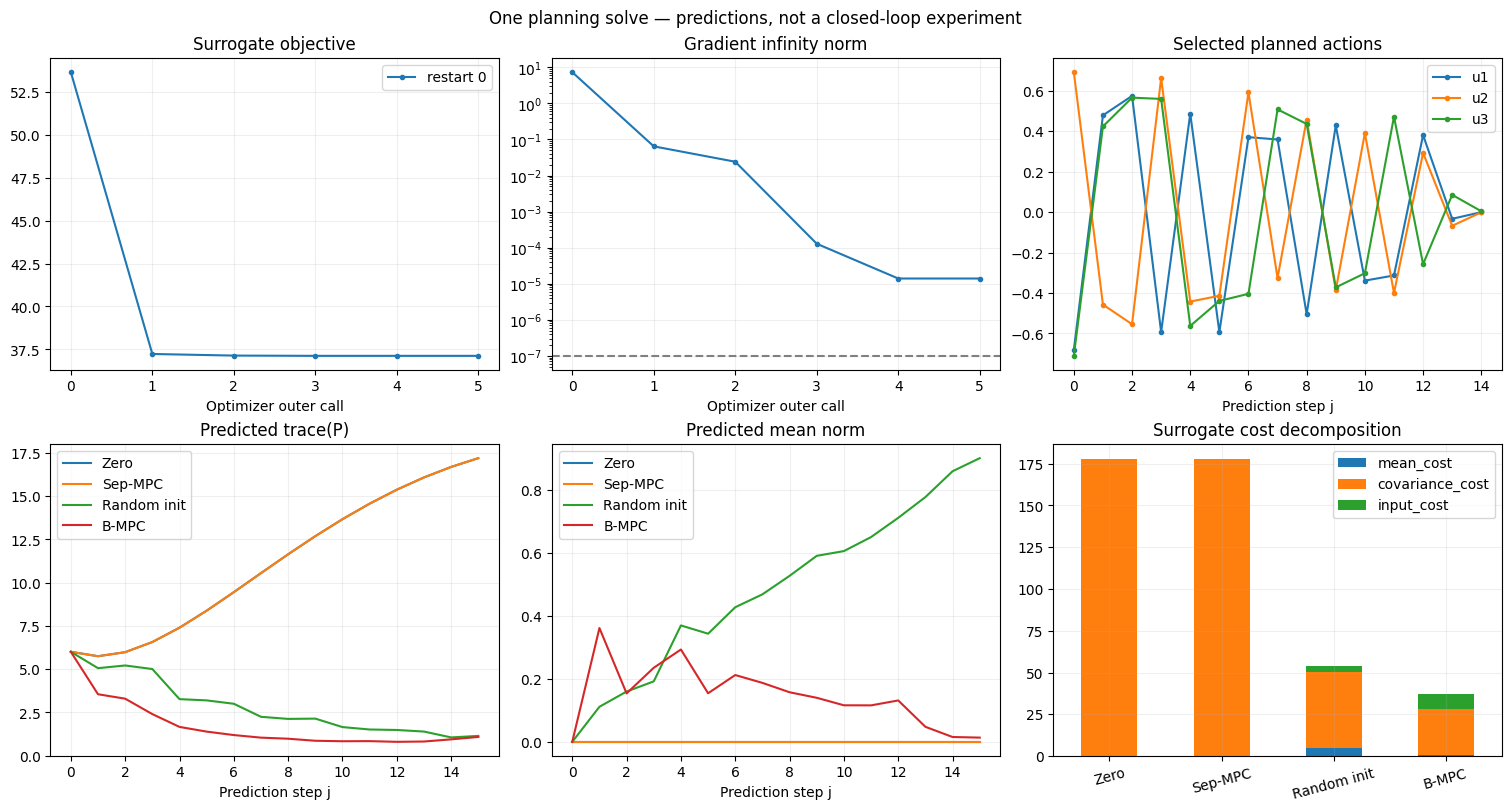

In [40]:
planning_result = run_planning_experiment(demo_cfg, system)

# T = 300：
# full_cfg = make_settings("double_integrator")
# full_result = run_closed_loop(full_cfg)
# report_closed_loop(full_result, "bmpc_results/full", print_steps=True)

# Fixed H, cfg.trials=10：
# repeated_result = run_sweep(cfg, "bmpc_results/repeated", horizons=(cfg.H,))

# cfg.horizons all H, all trials：
# sweep_result = run_sweep(cfg)

# double - random：
# random_cfg = make_settings("random")
# random_result = run_closed_loop(replace(random_cfg, T=40, lbfgs_outer_steps=4))
# report_closed_loop(random_result, "bmpc_results/random")

